# FairCredit AI — Exploratory Data Analysis (EDA)

## Objective
Explore the credit card default dataset using simple statistics and visualizations.

In this notebook, we will:
1. Compare default and non-default customers.
2. Explore credit limits and age.
3. Examine repayment status and default rates.
4. Compare bill and payment amounts.
5. View correlations between numeric features.

**Target column:** `default payment next month`

> These plots show patterns and associations in historical data. They do not prove that a feature causes default.

In [14]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use a consistent style for charts
sns.set_theme(style="whitegrid")

In [15]:
# Load the dataset
# This path assumes the notebook is inside the notebooks folder.
df = pd.read_excel(
    "../data/default of credit card clients.xls",
    header=1
)

# Give the target column a shorter name for easier use
df = df.rename(columns={"default payment next month": "DEFAULT"})

# Display a few rows
display(df.head())

/tmp/ipykernel_31039/74917288.py:3: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [16]:
# Check the dataset size and target counts
print("Dataset shape:", df.shape)
print("\nTarget counts:")
print(df["DEFAULT"].value_counts().sort_index())

print("\nTarget percentages:")
print((df["DEFAULT"].value_counts(normalize=True).sort_index() * 100).round(2))

Dataset shape: (30000, 25)

Target counts:
DEFAULT
0    23364
1     6636
Name: count, dtype: int64

Target percentages:
DEFAULT
0    77.88
1    22.12
Name: proportion, dtype: float64


## 1. Default vs. non-default customers

Target values:
- `0` = No default
- `1` = Default

This chart helps us see whether the two classes are balanced.

**Why this graph?** A count plot is used to compare how many customers belong to each default class.

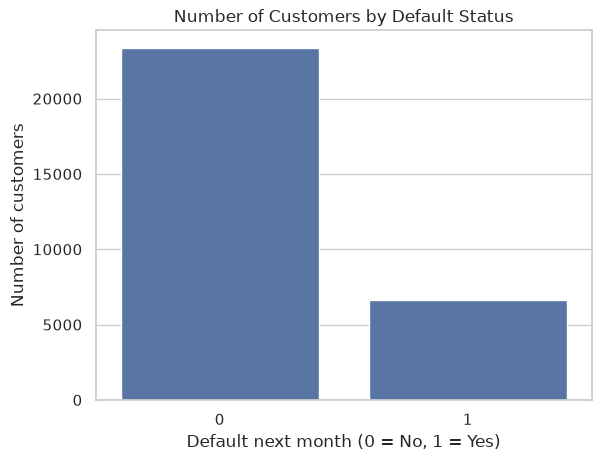

In [17]:
# Count plot for the target
sns.countplot(data=df, x="DEFAULT")
plt.title("Number of Customers by Default Status")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.show()

## 2. Credit limit distribution

`LIMIT_BAL` represents the assigned credit limit. We compare its distribution for customers who did and did not default.

**Why this graph?** A histogram is used to see the distribution of credit limits and compare it across default groups.

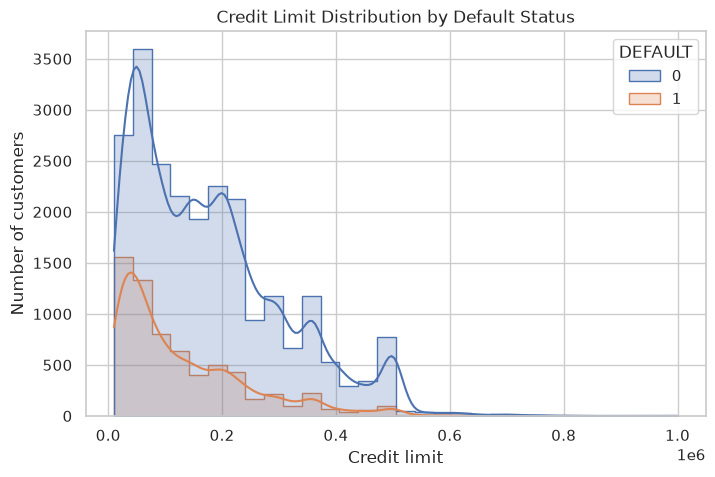

In [18]:
# Distribution of credit limits
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="LIMIT_BAL", hue="DEFAULT", bins=30, kde=True, element="step")
plt.title("Credit Limit Distribution by Default Status")
plt.xlabel("Credit limit")
plt.ylabel("Number of customers")
plt.show()

## 3. Age distribution

This chart shows the ages of customers in the dataset, separated by default status.

**Why this graph?** A histogram is used to see the age distribution and whether the groups overlap.

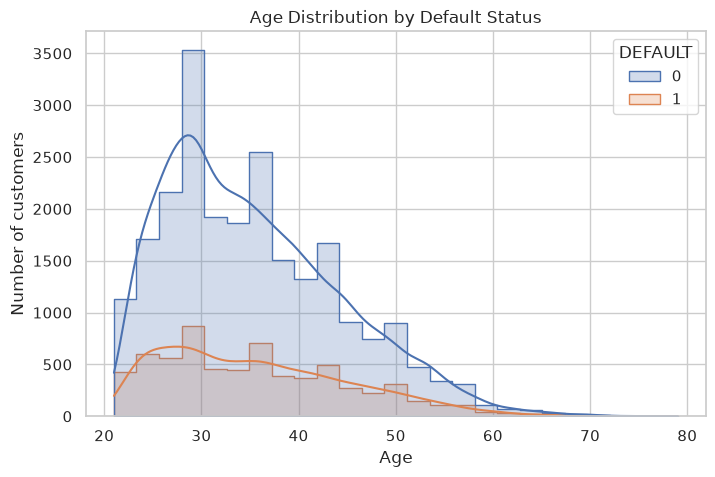

In [19]:
# Distribution of customer ages
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="AGE", hue="DEFAULT", bins=25, element="step", kde=True)
plt.title("Age Distribution by Default Status")
plt.xlabel("Age")
plt.ylabel("Number of customers")
plt.show()

## 4. Repayment status and default rate

`PAY_0` records repayment status for the most recent period in this dataset. We calculate the observed default rate for each status code.

The chart describes an association in this historical dataset; it does not establish cause and effect.

PAY_0 code	Meaning -> <br>
-2	= No consumption recorded (as described in the dataset's coding)<br>
-1	= Paid duly<br>
0	= Revolving credit / no payment delay recorded in this category<br>
1	= Payment delayed by 1 month<br>
2	= Payment delayed by 2 months<br>
3 or higher	Increasingly longer payment delays<br>

**Why this graph?** A bar chart is used to compare the observed default rate across discrete repayment-status categories.

Default rate by PAY_0 status (%):
PAY_0
-2    13.23
-1    16.78
 0    12.81
 1    33.95
 2    69.14
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: DEFAULT, dtype: float64


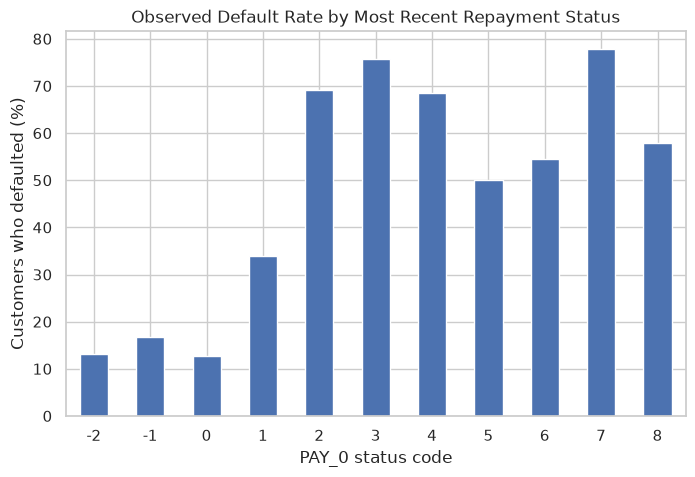

In [20]:
# Calculate default rate for each PAY_0 status
default_rate_by_pay0 = df.groupby("PAY_0")["DEFAULT"].mean() * 100

print("Default rate by PAY_0 status (%):")
print(default_rate_by_pay0.round(2))

# Plot the rates
default_rate_by_pay0.plot(kind="bar", figsize=(8, 5))
plt.title("Observed Default Rate by Most Recent Repayment Status")
plt.xlabel("PAY_0 status code")
plt.ylabel("Customers who defaulted (%)")
plt.xticks(rotation=0)
plt.show()

## 5. Bill amounts and payment amounts

We compare the most recent bill amount (`BILL_AMT1`) and payment amount (`PAY_AMT1`) across the two target groups. Boxplots help show the median and spread.

Financial amounts can be highly skewed, so some extreme values may make the central boxes look small.

**Why this graph?** A boxplot is used to compare the median, spread, and possible outliers in bill amounts between the two groups.

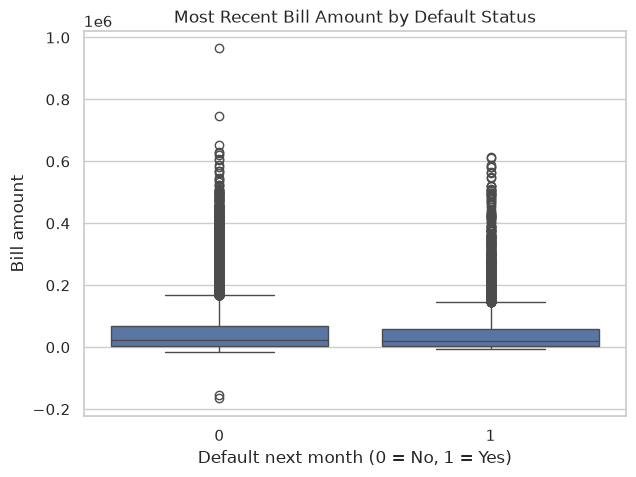

In [21]:
# Compare the most recent bill amount
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="DEFAULT", y="BILL_AMT1")
plt.title("Most Recent Bill Amount by Default Status")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Bill amount")
plt.show()

**Why this graph?** A boxplot is used to compare the median, spread, and possible outliers in payment amounts between the two groups.

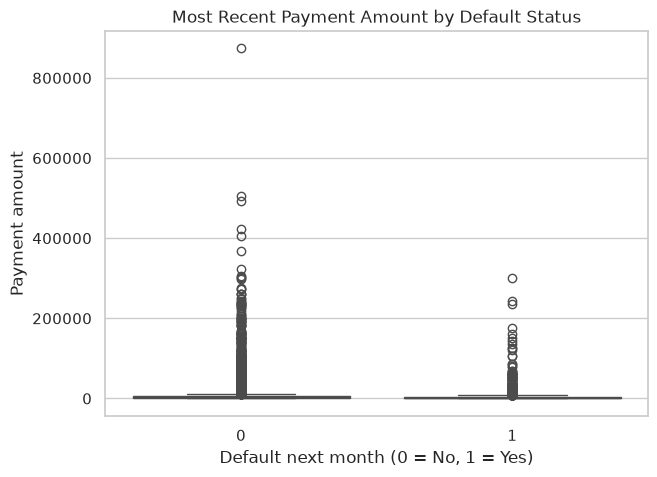

In [22]:
# Compare the most recent payment amount
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="DEFAULT", y="PAY_AMT1")
plt.title("Most Recent Payment Amount by Default Status")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Payment amount")
plt.show()

## 6. Compare average values

The table below compares average credit limits, bills, and payments for the two target groups. Averages can be affected by extreme values, so read them alongside the plots.

In [23]:
# Compare average financial amounts by target
summary = df.groupby("DEFAULT")[[
    "LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"
]].mean().round(2)

display(summary)

,LIMIT_BAL,BILL_AMT1,PAY_AMT1
DEFAULT,,,
0,178099.73,51994.23,6307.34
1,130109.66,48509.16,3397.04


## 7. Correlation heatmap

Correlation measures how strongly numeric variables move together in a linear way. It does not prove causation.

We remove `ID` because it is an identifier, not a meaningful financial measurement.

**Why this graph?** A heatmap is used to view many pairwise correlations at once; values near -1 or +1 indicate stronger linear relationships, while values near 0 indicate weaker ones.

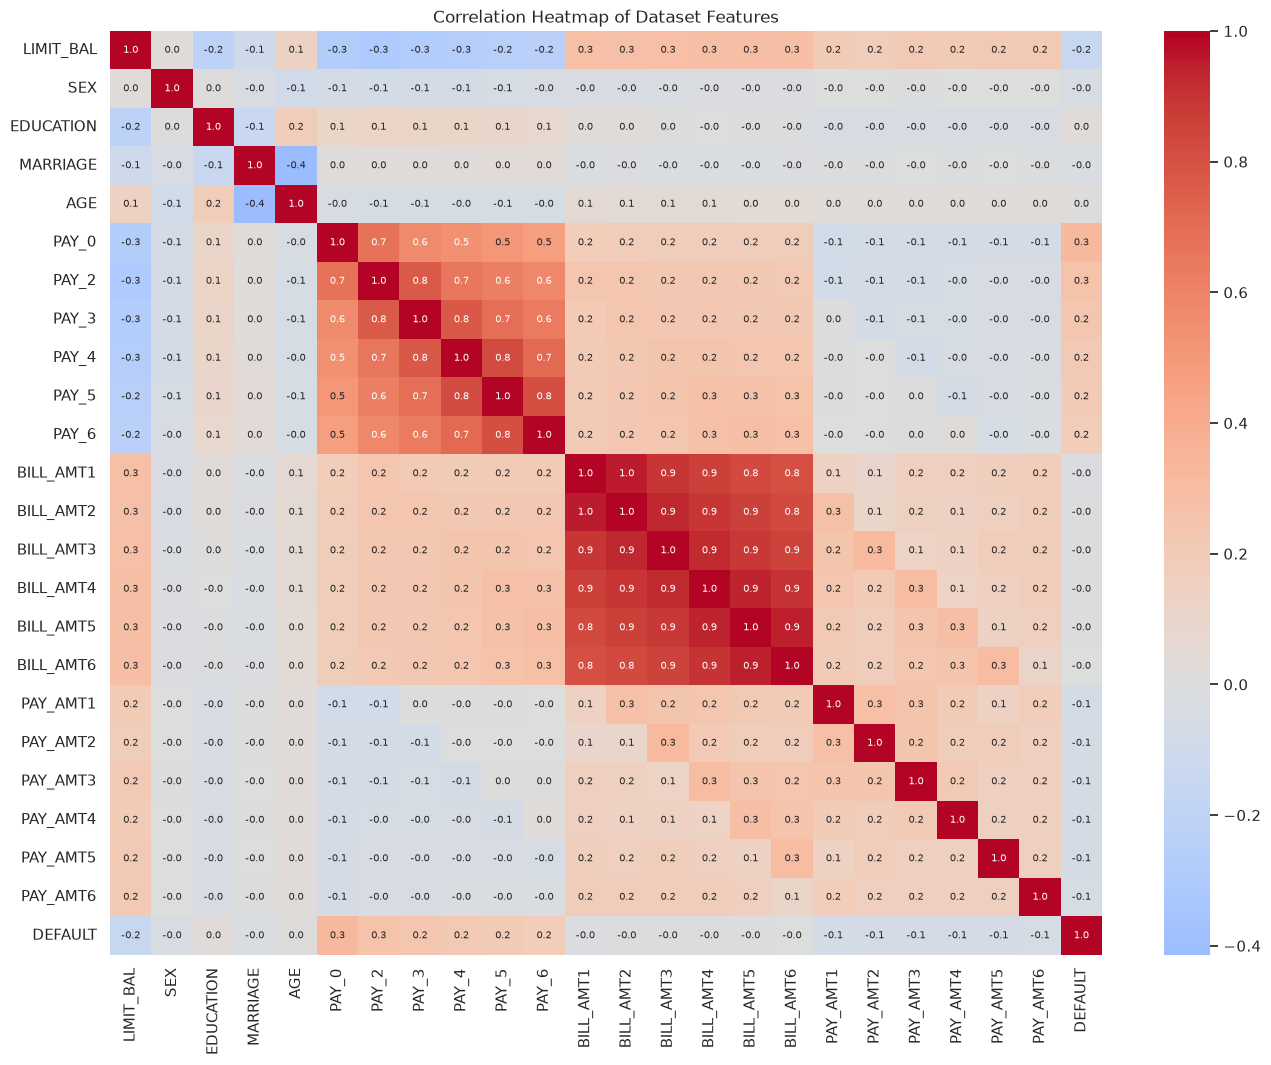

In [24]:
# Select numeric columns and remove the ID column
correlation_data = df.drop(columns=["ID"])

# Calculate correlations
correlation = correlation_data.corr()

# Draw the heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlation Heatmap of Dataset Features")
plt.show()

In [25]:
# Show features with the strongest absolute correlation to the target
target_correlations = correlation["DEFAULT"].drop("DEFAULT")
target_correlations = target_correlations.reindex(
    target_correlations.abs().sort_values(ascending=False).index
)

print("Features most correlated with DEFAULT:")
display(target_correlations.head(10).to_frame(name="Correlation with DEFAULT"))

Features most correlated with DEFAULT:


,Correlation with DEFAULT
PAY_0,0.324794
PAY_2,0.263551
PAY_3,0.235253
PAY_4,0.216614
PAY_5,0.204149
PAY_6,0.186866
LIMIT_BAL,-0.153520
PAY_AMT1,-0.072929
PAY_AMT2,-0.058579
PAY_AMT4,-0.056827


## 8. EDA findings — complete after reviewing your plots

After running all cells, write down what you observe. Use the actual plots and tables rather than assuming a result.

- **Class distribution:** Is default less common than non-default?
- **Credit limit:** Do the distributions differ between the two groups?
- **Age:** Are there visible differences, or do the distributions overlap?
- **Repayment status:** Which `PAY_0` categories have higher observed default rates?
- **Bills and payments:** How do the distributions compare, and are there extreme values?
- **Correlation:** Which features have the strongest positive or negative correlations with the target?

## Conclusion

This notebook explores patterns in the historical credit card default dataset. The findings will guide the next stage: preprocessing and training classification models.

Remember: patterns in EDA are not proof of causation, and findings from this historical Taiwan dataset should not be assumed to apply directly to current lending in India.